# TX power sweep analysis

Compares the LoRa link signal for the different **TX power configurations** logged by
`mdbpower_sweep_test.py` (one CSV per configuration in `runs_power_csv/`). This is the
power-focused counterpart of `analyze_be_sweep.py`: instead of a per-file report it puts
all configurations next to each other.

Only `tx_power` changes between the configurations (frequency, SF, BW and CR are fixed).
The sweep is **interleaved** (one round per power, then the next power, ... repeated), so
every power level sees the same time span, temperature and interference - differences
between powers are not caused by drift over the days the sweep ran.

Sections
1. Load & sanity checks
2. Per-power summary (RSSI, SNR, PDR, latency)
3. Power vs signal: RSSI / SNR / PDR curves, step gain and saturation
4. Distributions per power
5. Per-link view (heatmaps, slope, minimum power for reliable delivery)
6. Per-node view and link asymmetry
7. RSSI vs SNR
8. Stability over time and temperature
9. Key numbers and export

Signal quality (RSSI/SNR) only counts correctly received packets (`ok_match == 1`).
Caveat: at low power the weakest links drop out of that sample, so mean RSSI is slightly
biased upwards there (survivorship) - read it together with the PDR.

In [1]:
from __future__ import annotations

import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

try:
    from IPython.display import display
except ImportError:  # plain-python run
    display = print

# =========================
# CONFIG (adjust as needed!)
# =========================
CSV_DIR = Path("../results/runs_power_csv")                   # written by mdbpower_sweep_test.py
OUT_SUMMARY_PATH = CSV_DIR / "power_summary.csv"
OUT_LINKS_PATH = CSV_DIR / "power_link_stats.csv"  # per (tx_power, sender, receiver)

WINDOW_HOURS = None        # None = whole file; e.g. 24.0 = only the last 24h (relative to the newest sample)

REF_POWERS = [0, 5, 10, 14, 22]   # highlighted in the histogram / matrix / time plots
PDR_TARGET_PCT = 95.0             # "reliable" link for the minimum-power analysis
SAT_STEP_DB = 0.5                 # mean RSSI gain per +1 dBm below this = radio output saturated
ASYM_POWER = 10                   # power level used for the A->B vs B->A comparison
PDR_DIFF_POWERS = (0, 22)         # (low, high) for the PDR change matrix

# Firmware assumptions that are not part of the CSVs (same as analyze_be_sweep.py)
ASSUMED_PREAMBLE_LEN = 8
ASSUMED_CRC_ENABLED = True
ASSUMED_EXPLICIT_HEADER = True
STAT_PY_PATH = Path("../scripts/stat.py")

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e3e3e3",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.frameon": False,
})

INK = "#1f2933"       # neutral ink for reference lines
ACCENT = "#1b6ca8"    # single-series accent
WARN = "#c0392b"      # threshold / saturation markers
# Okabe-Ito (colorblind-safe) - one fixed colour per node id, in node order
NODE_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]

In [2]:
def _load_stat_module():
    """Loads stat.py via its file path (the name 'stat' collides with the standard library)
    and puts its directory on sys.path so its own `import config` works."""
    stat_dir = str(STAT_PY_PATH.resolve().parent)
    added = stat_dir not in sys.path
    if added:
        sys.path.insert(0, stat_dir)
    try:
        spec = importlib.util.spec_from_file_location("ebb_stat", STAT_PY_PATH)
        module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(module)
        return module
    finally:
        if added:
            sys.path.remove(stat_dir)


try:
    stat = _load_stat_module()
except Exception as e:  # ToA / mW columns are optional
    print(f"stat.py not usable ({e}); ToA is skipped and mW is computed directly")
    stat = None


def load_power_csvs(csv_dir: Path) -> pd.DataFrame:
    paths = sorted(p for p in csv_dir.glob("results_*.csv") if p.is_file())
    if not paths:
        raise FileNotFoundError(f"No results_*.csv under {csv_dir.resolve()} - run mdbpower_sweep_test.py first.")
    frames = []
    for p in paths:
        f = pd.read_csv(p)
        if f.empty:
            print(f"[skip] {p.name}: empty")
            continue
        f["csv_file"] = p.name
        frames.append(f)
    out = pd.concat(frames, ignore_index=True)
    out["pc_ts"] = pd.to_datetime(out["pc_ts"])
    out["ok"] = out["ok_match"] == 1
    out["link"] = out["sender_id"].astype(str) + "→" + out["receiver_id"].astype(str)
    return out


df = load_power_csvs(CSV_DIR)
if WINDOW_HOURS is not None:
    df = df[df["pc_ts"] >= df["pc_ts"].max() - pd.Timedelta(hours=WINDOW_HOURS)].copy()

ok = df[df["ok"]]
powers = sorted(df["tx_power"].unique())
nodes = sorted(set(df["sender_id"]) | set(df["receiver_id"]))
ref = [p for p in REF_POWERS if p in powers]

# One sequential colour per power level (light = low power, dark = high power)
_cmap = plt.get_cmap("Blues")
POWER_COLOR = {p: _cmap(0.3 + 0.7 * i / max(len(powers) - 1, 1)) for i, p in enumerate(powers)}

print(f"{len(df):,} link samples from {df['csv_file'].nunique()} configurations, "
      f"{len(powers)} power levels ({powers[0]}..{powers[-1]} dBm), nodes {nodes}")
print(f"time span: {df['pc_ts'].min()} .. {df['pc_ts'].max()} "
      f"({(df['pc_ts'].max() - df['pc_ts'].min()).total_seconds() / 3600:.1f} h)")

stat.py not usable ([Errno 2] No such file or directory: '/home/duchieuvn/Code/stefan/SOFTWARE/master/stat.py'); ToA is skipped and mW is computed directly
287,532 link samples from 23 configurations, 23 power levels (0..22 dBm), nodes [1, 2, 3, 4, 5, 6, 7, 8]
time span: 2026-09-18 14:31:31 .. 2026-09-21 13:23:23 (70.9 h)


## 1. Sanity checks
Only `tx_power` should differ between configurations, and each power should have a
similar number of rounds (the sweep may have been stopped in the middle of a pass).

In [3]:
print("Fixed radio parameters (should be a single row):")
display(df[["freq_mhz", "sf", "bw_khz", "cr_denom", "payload_len"]].drop_duplicates())

per_power = df.groupby("tx_power").agg(
    rounds=("round_id", "nunique"),
    samples=("ok", "size"),
    first=("pc_ts", "min"),
    last=("pc_ts", "max"),
)
display(per_power)
if per_power["rounds"].nunique() > 1:
    print("NOTE: rounds per power differ - the sweep was cut in the middle of a pass.")

first = df.iloc[0]
if stat is not None:
    toa = stat.calculate_time_on_air_ms(
        sf=int(first["sf"]), bw_khz=float(first["bw_khz"]), cr_denom=int(first["cr_denom"]),
        preamble_len=ASSUMED_PREAMBLE_LEN, payload_bytes=int(first["payload_len"]),
        crc_enabled=ASSUMED_CRC_ENABLED, explicit_header=ASSUMED_EXPLICIT_HEADER, ldro="auto")
    print(f"Time on air (identical for all powers): {toa['toa_ms']:.1f} ms")

Fixed radio parameters (should be a single row):


,freq_mhz,sf,bw_khz,cr_denom,payload_len
0,433.1,12,125,8,43


,rounds,samples,first,last
tx_power,,,,
0,224,12544,2026-09-18 14:31:31,2026-09-21 13:19:49
1,224,12544,2026-09-18 14:32:15,2026-09-21 13:20:34
2,224,12544,2026-09-18 14:33:00,2026-09-21 13:21:29
3,224,12544,2026-09-18 14:33:45,2026-09-21 13:22:14
4,224,12544,2026-09-18 14:34:30,2026-09-21 13:22:58
5,224,12516,2026-09-18 14:35:15,2026-09-21 13:23:23
6,223,12488,2026-09-18 14:36:00,2026-09-21 13:05:27
7,223,12488,2026-09-18 14:36:45,2026-09-21 13:06:22
8,223,12488,2026-09-18 14:37:30,2026-09-21 13:07:17


NOTE: rounds per power differ - the sweep was cut in the middle of a pass.


## 2. Per-power summary

In [4]:
def q(p):
    return lambda s: s.quantile(p)


sig = ok.groupby("tx_power").agg(
    rssi_mean=("rssi", "mean"), rssi_median=("rssi", "median"), rssi_std=("rssi", "std"),
    rssi_min=("rssi", "min"), rssi_p5=("rssi", q(0.05)), rssi_p95=("rssi", q(0.95)),
    snr_mean=("snr", "mean"), snr_median=("snr", "median"), snr_std=("snr", "std"),
    snr_min=("snr", "min"), snr_p5=("snr", q(0.05)), snr_p95=("snr", q(0.95)),
    e2e_ms_median=("e2e_ms", "median"), e2e_ms_p95=("e2e_ms", q(0.95)),
)
delivery = df.groupby("tx_power")["ok"].agg(attempts="size", ok_links="sum")
delivery["timeouts"] = delivery["attempts"] - delivery["ok_links"]
delivery["pdr_pct"] = 100.0 * delivery["ok_links"] / delivery["attempts"]

summary = delivery.join(sig)
_dp = summary.index.to_series().diff()
summary["rssi_step_db"] = summary["rssi_mean"].diff() / _dp   # dB gained per +1 dBm TX power
summary["snr_step_db"] = summary["snr_mean"].diff() / _dp
if stat is not None:
    summary["tx_mw"] = [stat.calculate_power_mw(p)["conducted_mw"] for p in summary.index]
else:
    summary["tx_mw"] = 10.0 ** (summary.index.to_series() / 10.0)
summary.index.name = "tx_power_dbm"
display(summary.round(2))

,attempts,ok_links,timeouts,pdr_pct,rssi_mean,rssi_median,rssi_std,rssi_min,rssi_p5,rssi_p95,...,snr_median,snr_std,snr_min,snr_p5,snr_p95,e2e_ms_median,e2e_ms_p95,rssi_step_db,snr_step_db,tx_mw
tx_power_dbm,,,,,,,,,,,,,,,,,,,,,
0,12544,12527,17,99.86,-87.31,-87.0,14.65,-127.5,-116.0,-64.0,...,4.5,2.57,-13.5,-1.5,5.5,4276.95,4738.82,NaN,NaN,1.00
1,12544,12524,20,99.84,-86.49,-87.0,14.67,-127.5,-115.0,-63.0,...,4.5,2.45,-17.2,-1.0,5.5,4271.10,4736.66,0.82,0.08,1.26
2,12544,12504,40,99.68,-85.38,-86.0,14.69,-127.5,-114.0,-62.0,...,4.7,2.32,-19.5,-0.5,5.7,4271.27,4738.04,1.11,0.14,1.58
3,12544,12511,33,99.74,-84.70,-85.0,14.69,-126.0,-114.0,-61.0,...,4.7,2.20,-10.2,-0.2,5.7,4272.25,4737.42,0.68,0.06,2.00
4,12544,12489,55,99.56,-83.45,-84.0,14.72,-124.0,-112.0,-60.0,...,4.7,2.04,-7.7,0.0,5.7,4269.45,4736.72,1.24,0.13,2.51
5,12516,12455,61,99.51,-82.69,-83.0,14.73,-123.0,-112.0,-59.0,...,4.7,1.96,-6.5,0.0,5.7,4268.68,4736.83,0.76,0.08,3.16
6,12488,12428,60,99.52,-81.67,-82.0,14.76,-127.5,-111.0,-58.0,...,4.7,1.88,-13.2,0.0,5.7,4275.48,4738.36,1.02,0.09,3.98
7,12488,12415,73,99.42,-80.55,-81.0,14.77,-127.5,-109.0,-57.0,...,4.7,1.79,-12.0,0.0,5.7,4268.82,4736.19,1.12,0.08,5.01
8,12488,12407,81,99.35,-79.57,-80.0,14.77,-127.5,-109.0,-56.0,...,4.7,1.76,-19.5,0.0,5.7,4268.98,4736.31,0.97,0.11,6.31


## 3. Power vs signal
Ideal behaviour: RSSI/SNR rise 1 dB per +1 dBm TX power (dashed line, anchored at the lowest
power). Where the measured curve flattens, the radio no longer increases its real output
(PA limit / receiver front-end). The saturation point is found automatically
(`SAT_STEP_DB`) and marked with the dotted line.

RSSI gain per +1 dBm stays >= 0.5 dB up to 13 dBm -> saturated from 14 dBm upwards


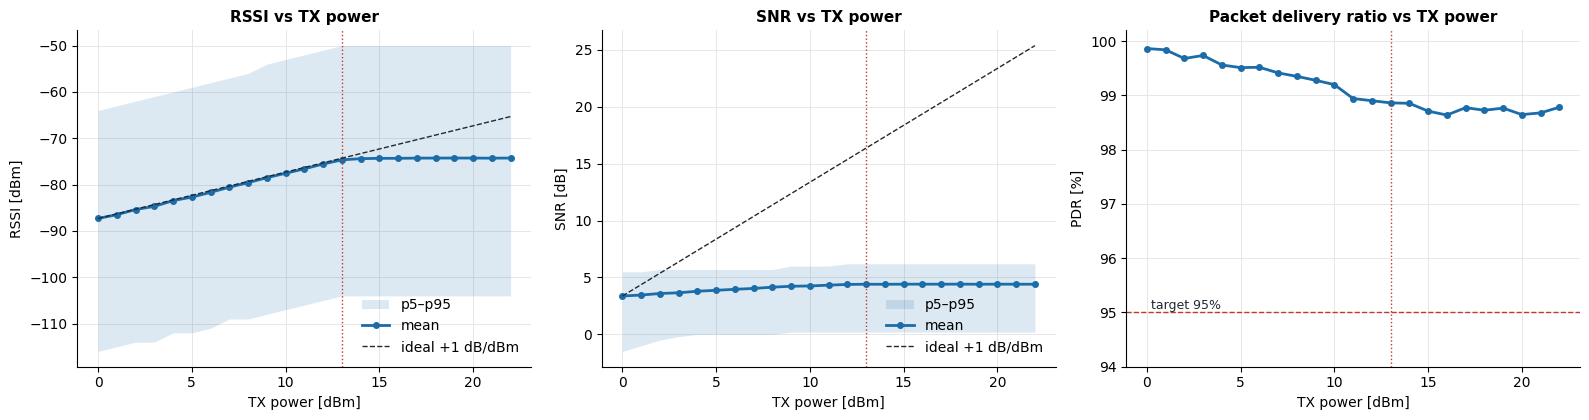

In [5]:
steps = summary["rssi_step_db"].dropna()
strong = steps[steps >= SAT_STEP_DB]
sat_power = int(strong.index.max()) if len(strong) else int(summary.index.min())
linear_powers = [p for p in powers if p <= sat_power]
print(f"RSSI gain per +1 dBm stays >= {SAT_STEP_DB} dB up to {sat_power} dBm "
      f"-> saturated from {sat_power + 1} dBm upwards")

x = summary.index.to_numpy(float)
ideal_rssi = summary["rssi_mean"].iloc[0] + (x - x[0])
ideal_snr = summary["snr_mean"].iloc[0] + (x - x[0])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

ax = axes[0]
ax.fill_between(x, summary["rssi_p5"], summary["rssi_p95"], color=ACCENT, alpha=0.15, lw=0, label="p5–p95")
ax.plot(x, summary["rssi_mean"], color=ACCENT, lw=2, marker="o", ms=4, label="mean")
ax.plot(x, ideal_rssi, color=INK, lw=1, ls="--", label="ideal +1 dB/dBm")
ax.axvline(sat_power, color=WARN, lw=1, ls=":")
ax.set(title="RSSI vs TX power", xlabel="TX power [dBm]", ylabel="RSSI [dBm]")
ax.legend(loc="lower right")

ax = axes[1]
ax.fill_between(x, summary["snr_p5"], summary["snr_p95"], color=ACCENT, alpha=0.15, lw=0, label="p5–p95")
ax.plot(x, summary["snr_mean"], color=ACCENT, lw=2, marker="o", ms=4, label="mean")
ax.plot(x, ideal_snr, color=INK, lw=1, ls="--", label="ideal +1 dB/dBm")
ax.axvline(sat_power, color=WARN, lw=1, ls=":")
ax.set(title="SNR vs TX power", xlabel="TX power [dBm]", ylabel="SNR [dB]")
ax.legend(loc="lower right")

ax = axes[2]
ax.plot(x, summary["pdr_pct"], color=ACCENT, lw=2, marker="o", ms=4)
ax.axhline(PDR_TARGET_PCT, color=WARN, lw=1, ls="--")
ax.text(x[0], PDR_TARGET_PCT, f" target {PDR_TARGET_PCT:g}%", color=INK, va="bottom", fontsize=9)
ax.axvline(sat_power, color=WARN, lw=1, ls=":")
lo = min(summary["pdr_pct"].min(), PDR_TARGET_PCT) - 1
ax.set(title="Packet delivery ratio vs TX power", xlabel="TX power [dBm]", ylabel="PDR [%]", ylim=(lo, 100.2))

plt.tight_layout()
plt.show()

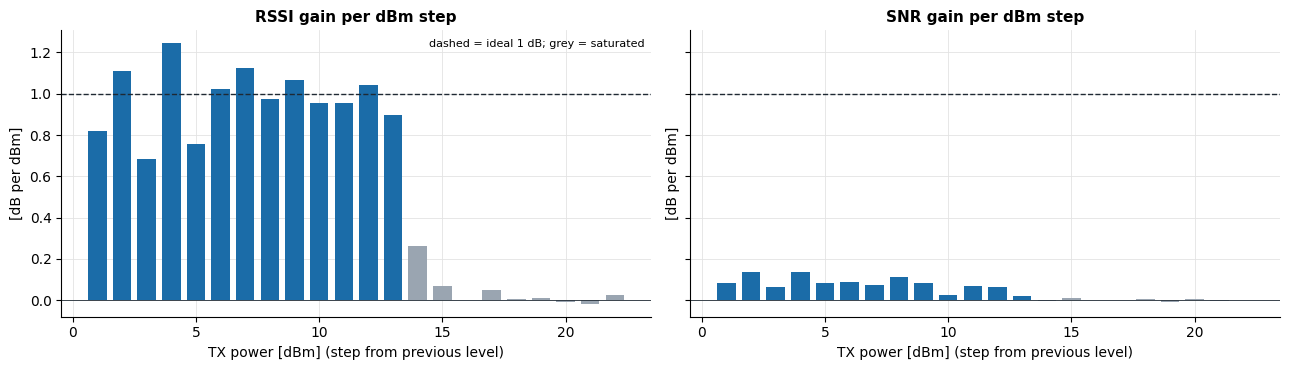

In [6]:
# Measured RSSI/SNR gain per +1 dBm step (ideal = 1 dB)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, title in [(axes[0], "rssi_step_db", "RSSI gain per dBm step"),
                       (axes[1], "snr_step_db", "SNR gain per dBm step")]:
    s = summary[col].dropna()
    ax.bar(s.index, s.values, color=[ACCENT if p <= sat_power else "#9aa5b1" for p in s.index], width=0.75)
    ax.axhline(1.0, color=INK, lw=1, ls="--")
    ax.axhline(0.0, color=INK, lw=0.6)
    ax.set(title=title, xlabel="TX power [dBm] (step from previous level)", ylabel="[dB per dBm]")
axes[0].text(0.99, 0.97, "dashed = ideal 1 dB; grey = saturated", transform=axes[0].transAxes,
             ha="right", va="top", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Distributions per power
Box = quartiles, whiskers = p5/p95. A widening box at low power means links are
approaching the sensitivity limit; identical boxes at high power confirm saturation.

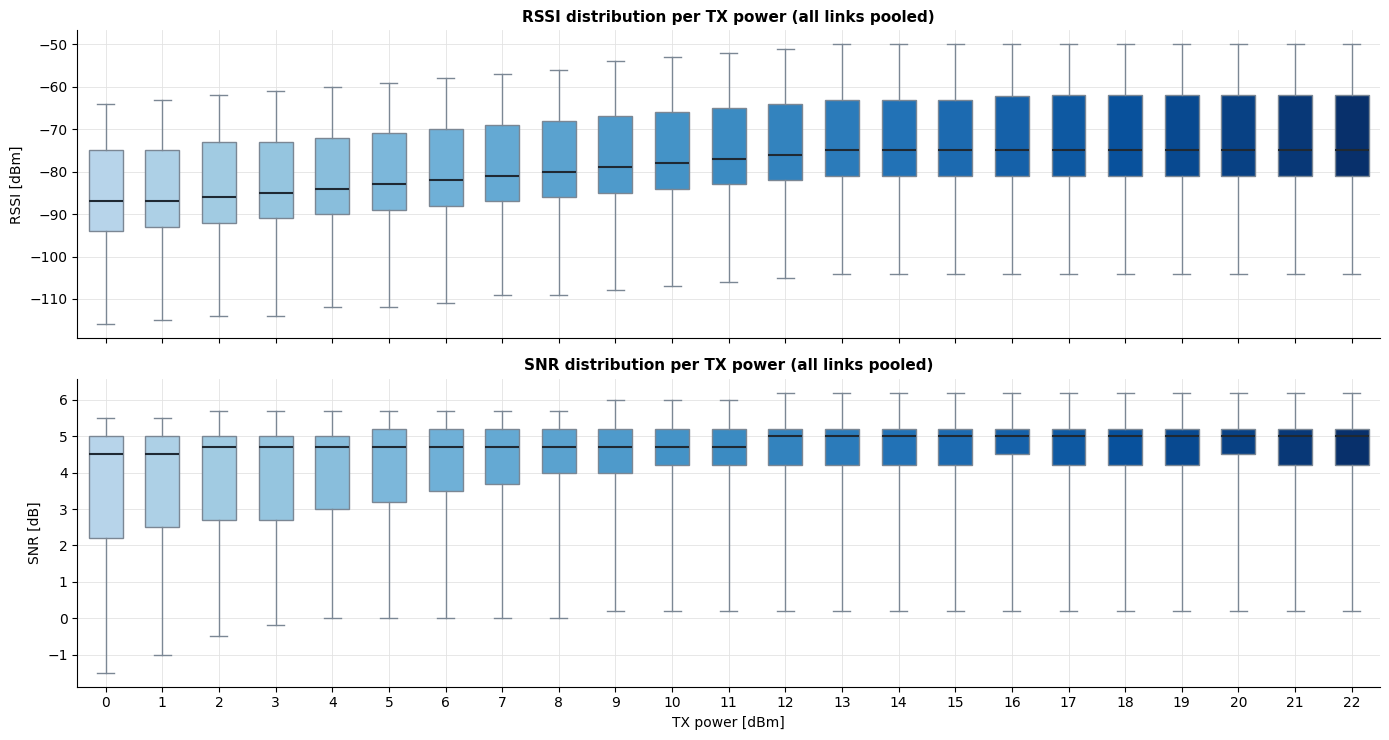

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)
for ax, col, label in [(axes[0], "rssi", "RSSI [dBm]"), (axes[1], "snr", "SNR [dB]")]:
    data = [ok.loc[ok["tx_power"] == p, col].dropna().to_numpy() for p in powers]
    bp = ax.boxplot(data, positions=powers, widths=0.6, whis=(5, 95), patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color="#7b8794"),
                    capprops=dict(color="#7b8794"), boxprops=dict(edgecolor="#7b8794"))
    for patch, p in zip(bp["boxes"], powers):
        patch.set_facecolor(POWER_COLOR[p])
    ax.set_ylabel(label)
axes[0].set_title("RSSI distribution per TX power (all links pooled)")
axes[1].set_title("SNR distribution per TX power (all links pooled)")
axes[1].set_xlabel("TX power [dBm]")
axes[1].set_xticks(powers)
plt.tight_layout()
plt.show()

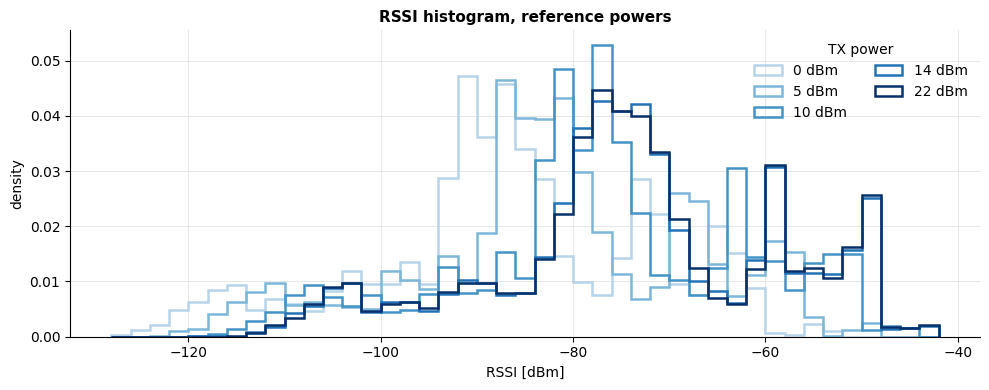

In [8]:
# RSSI histograms for the reference powers on a common axis
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(np.floor(ok["rssi"].min()), np.ceil(ok["rssi"].max()) + 2, 2)
for p in ref:
    ax.hist(ok.loc[ok["tx_power"] == p, "rssi"], bins=bins, histtype="step", lw=1.8,
            color=POWER_COLOR[p], density=True, label=f"{p} dBm")
ax.set(title="RSSI histogram, reference powers", xlabel="RSSI [dBm]", ylabel="density")
ax.legend(title="TX power", ncol=2)
plt.tight_layout()
plt.show()

## 5. Per-link view
Long table with one row per `(tx_power, sender, receiver)`; the same layout as
`link_stats.csv` from `analyze_be_sweep.py`, plus the power column.

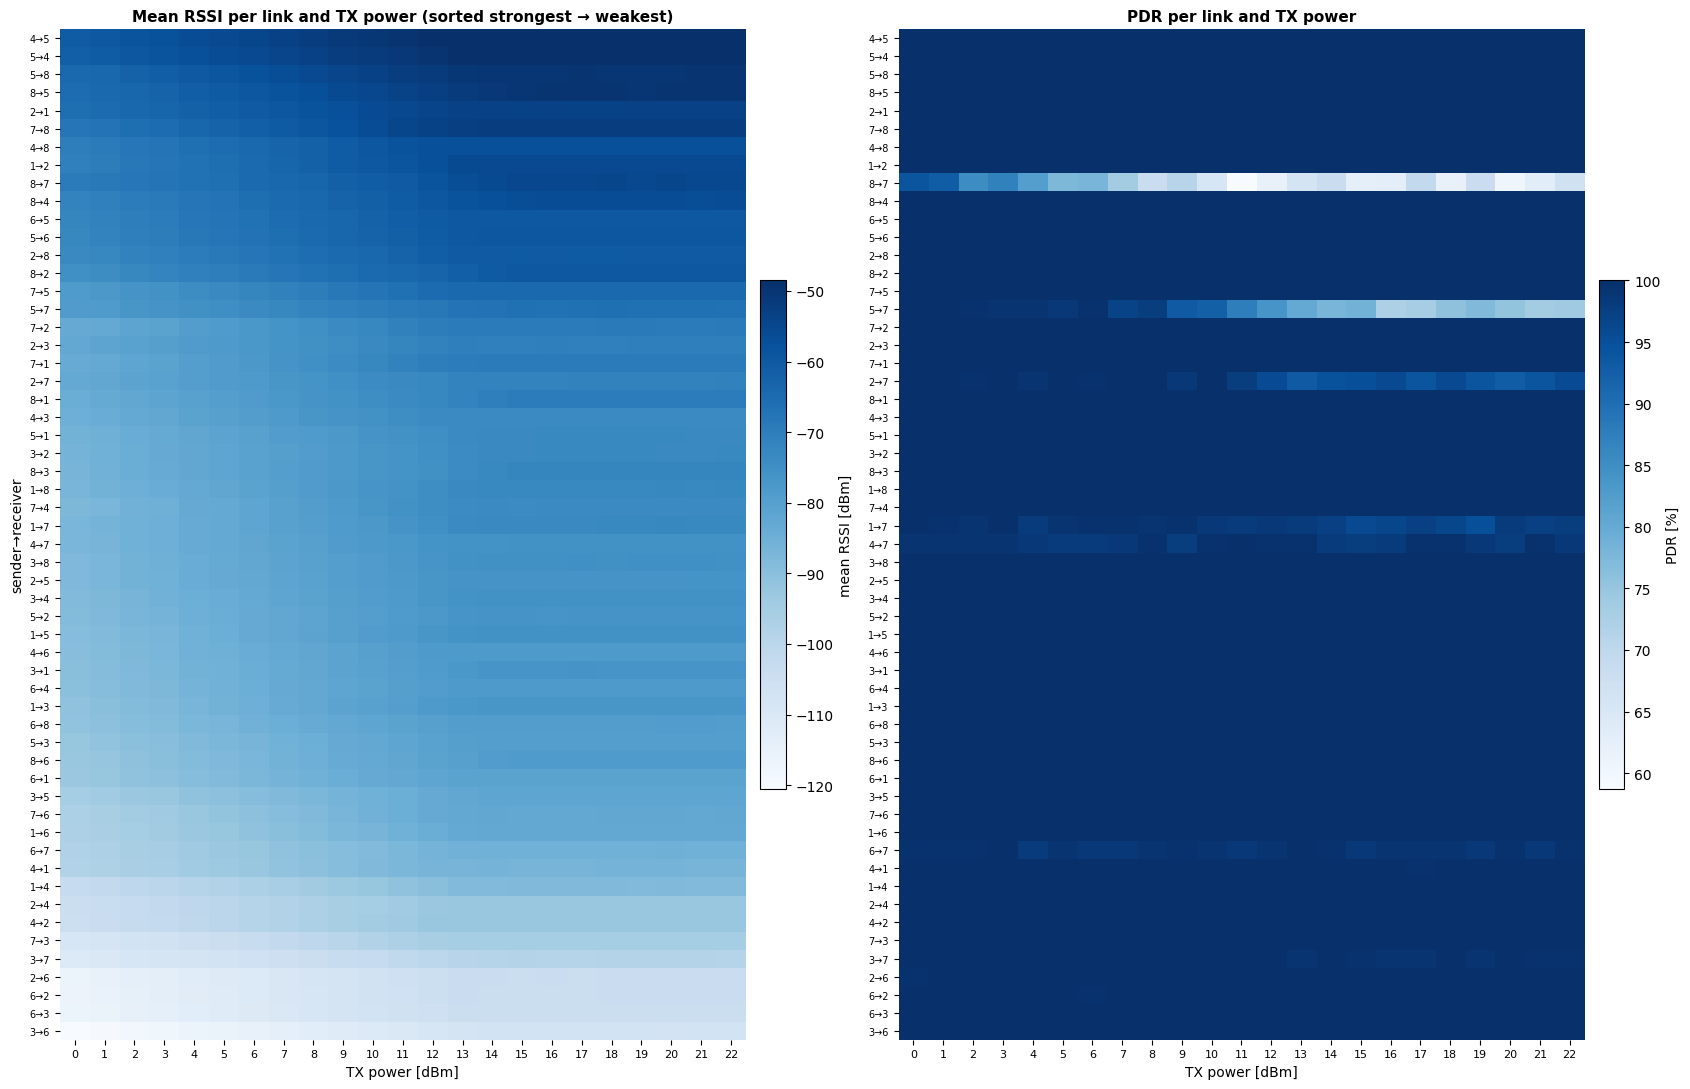

In [9]:
link_stats = (
    df.groupby(["tx_power", "sender_id", "receiver_id"])
      .agg(attempts=("ok", "size"), ok=("ok", "sum"))
      .join(ok.groupby(["tx_power", "sender_id", "receiver_id"]).agg(rssi_mean=("rssi", "mean"),
                                                                     snr_mean=("snr", "mean")))
      .reset_index()
)
link_stats["pdr_pct"] = 100.0 * link_stats["ok"] / link_stats["attempts"]
link_stats["link"] = link_stats["sender_id"].astype(str) + "→" + link_stats["receiver_id"].astype(str)

rssi_by_link = link_stats.pivot(index="link", columns="tx_power", values="rssi_mean")
pdr_by_link = link_stats.pivot(index="link", columns="tx_power", values="pdr_pct")
# order links from strongest to weakest (mean over the linear region)
link_order = rssi_by_link[linear_powers].mean(axis=1).sort_values(ascending=False).index
rssi_by_link = rssi_by_link.loc[link_order]
pdr_by_link = pdr_by_link.loc[link_order]


def heatmap(ax, mat: pd.DataFrame, cmap: str, label: str, vmin=None, vmax=None):
    im = ax.imshow(mat.to_numpy(float), aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_xticks(range(mat.shape[1]), [str(c) for c in mat.columns], fontsize=8)
    ax.set_yticks(range(mat.shape[0]), list(mat.index), fontsize=7)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.figure.colorbar(im, ax=ax, label=label, fraction=0.035, pad=0.02)
    return im


fig, axes = plt.subplots(1, 2, figsize=(17, 11))
heatmap(axes[0], rssi_by_link, "Blues", "mean RSSI [dBm]")
axes[0].set(title="Mean RSSI per link and TX power (sorted strongest → weakest)",
            xlabel="TX power [dBm]", ylabel="sender→receiver")
heatmap(axes[1], pdr_by_link, "Blues", "PDR [%]",
        vmin=max(0.0, min(90.0, float(np.nanmin(pdr_by_link.to_numpy())))), vmax=100)
axes[1].set(title="PDR per link and TX power", xlabel="TX power [dBm]")
plt.tight_layout()
plt.show()

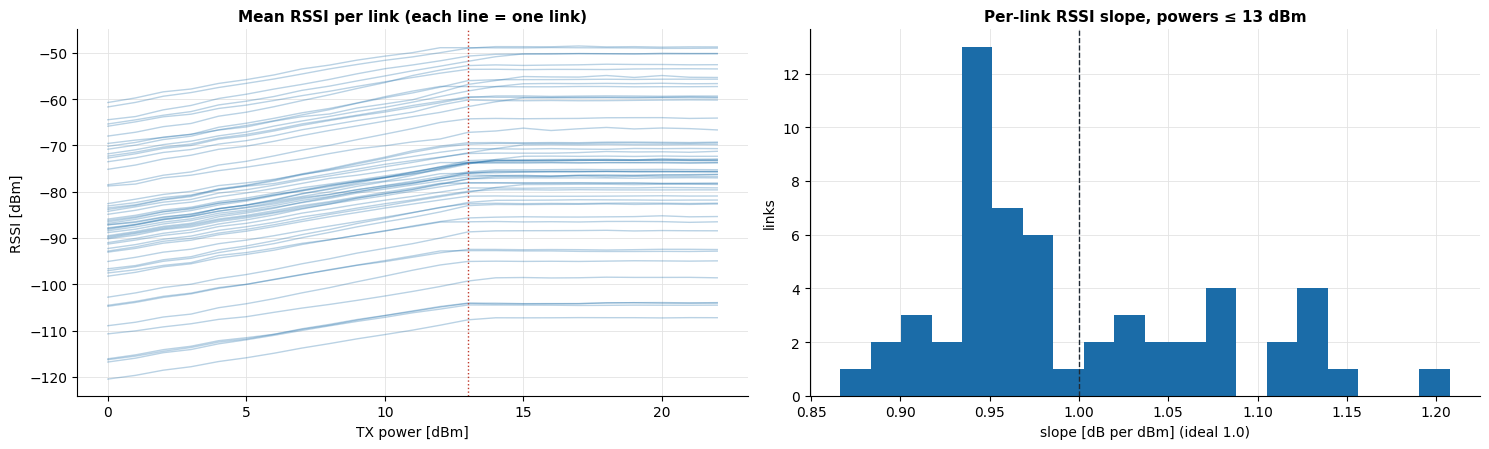

Links with the lowest slope (compressed / clipped links):


,slope_db_per_dbm
link,
3→7,0.87
2→7,0.89
5→7,0.89
4→3,0.91
2→5,0.91
2→3,0.92
4→7,0.92
6→7,0.93


In [10]:
# RSSI vs power for every link - the slope shows how faithfully each link follows the +1 dB/dBm law.
def slope_db_per_dbm(row: pd.Series) -> float:
    xs = row.index.to_numpy(float)
    ys = row.to_numpy(float)
    m = ~np.isnan(ys)
    return np.polyfit(xs[m], ys[m], 1)[0] if m.sum() >= 3 else np.nan


link_slopes = rssi_by_link[linear_powers].apply(slope_db_per_dbm, axis=1).rename("slope_db_per_dbm")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
for link in rssi_by_link.index:
    ax.plot(rssi_by_link.columns, rssi_by_link.loc[link], color=ACCENT, alpha=0.3, lw=1)
ax.axvline(sat_power, color=WARN, lw=1, ls=":")
ax.set(title="Mean RSSI per link (each line = one link)", xlabel="TX power [dBm]", ylabel="RSSI [dBm]")
axes[1].hist(link_slopes.dropna(), bins=20, color=ACCENT)
axes[1].axvline(1.0, color=INK, lw=1, ls="--")
axes[1].set(title=f"Per-link RSSI slope, powers ≤ {sat_power} dBm", xlabel="slope [dB per dBm] (ideal 1.0)",
            ylabel="links")
plt.tight_layout()
plt.show()

print("Links with the lowest slope (compressed / clipped links):")
display(link_slopes.sort_values().head(8).round(2).to_frame())

### Minimum power for a reliable link
Lowest tested TX power at which each link reaches `PDR_TARGET_PCT` **and keeps it** for all
higher powers (a single lucky level does not count).

Links that never reach a stable 95% PDR: 2 of 56


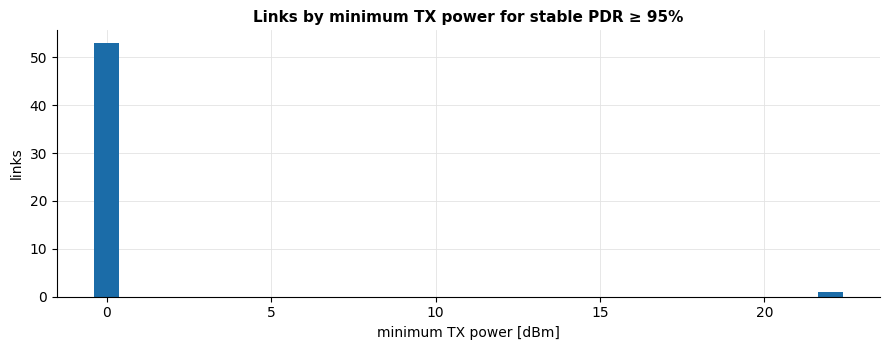

Most demanding links:


,min_power_dbm,slope_db_per_dbm,rssi@0dBm,pdr@0dBm
link,,,,
8→7,NaN,0.95,-69.57,94.2
5→7,NaN,0.89,-78.76,100.0
2→7,22.0,0.89,-83.08,100.0
4→5,0.0,0.96,-60.73,100.0
5→8,0.0,1.08,-64.45,100.0
8→5,0.0,1.06,-65.37,100.0
2→1,0.0,0.96,-65.85,100.0
5→4,0.0,0.98,-61.68,100.0
7→8,0.0,1.21,-67.98,100.0


In [11]:
def min_reliable_power(row: pd.Series):
    reliable = (row >= PDR_TARGET_PCT).to_numpy()
    idx = None
    for i in range(len(reliable) - 1, -1, -1):
        if not reliable[i]:
            break
        idx = i
    return row.index[idx] if idx is not None else np.nan


min_power = pdr_by_link.apply(min_reliable_power, axis=1).rename("min_power_dbm")
print(f"Links that never reach a stable {PDR_TARGET_PCT:g}% PDR: {int(min_power.isna().sum())} of {len(min_power)}")

fig, ax = plt.subplots(figsize=(9, 3.6))
counts = min_power.value_counts().reindex(powers, fill_value=0)
ax.bar(counts.index, counts.values, color=ACCENT, width=0.75)
ax.set(title=f"Links by minimum TX power for stable PDR ≥ {PDR_TARGET_PCT:g}%",
       xlabel="minimum TX power [dBm]", ylabel="links")
plt.tight_layout()
plt.show()

print("Most demanding links:")
display(pd.concat([min_power, link_slopes,
                   rssi_by_link[powers[0]].rename(f"rssi@{powers[0]}dBm"),
                   pdr_by_link[powers[0]].rename(f"pdr@{powers[0]}dBm")], axis=1)
        .sort_values("min_power_dbm", ascending=False, na_position="first").head(10).round(2))

## 6. Per-node view and link asymmetry

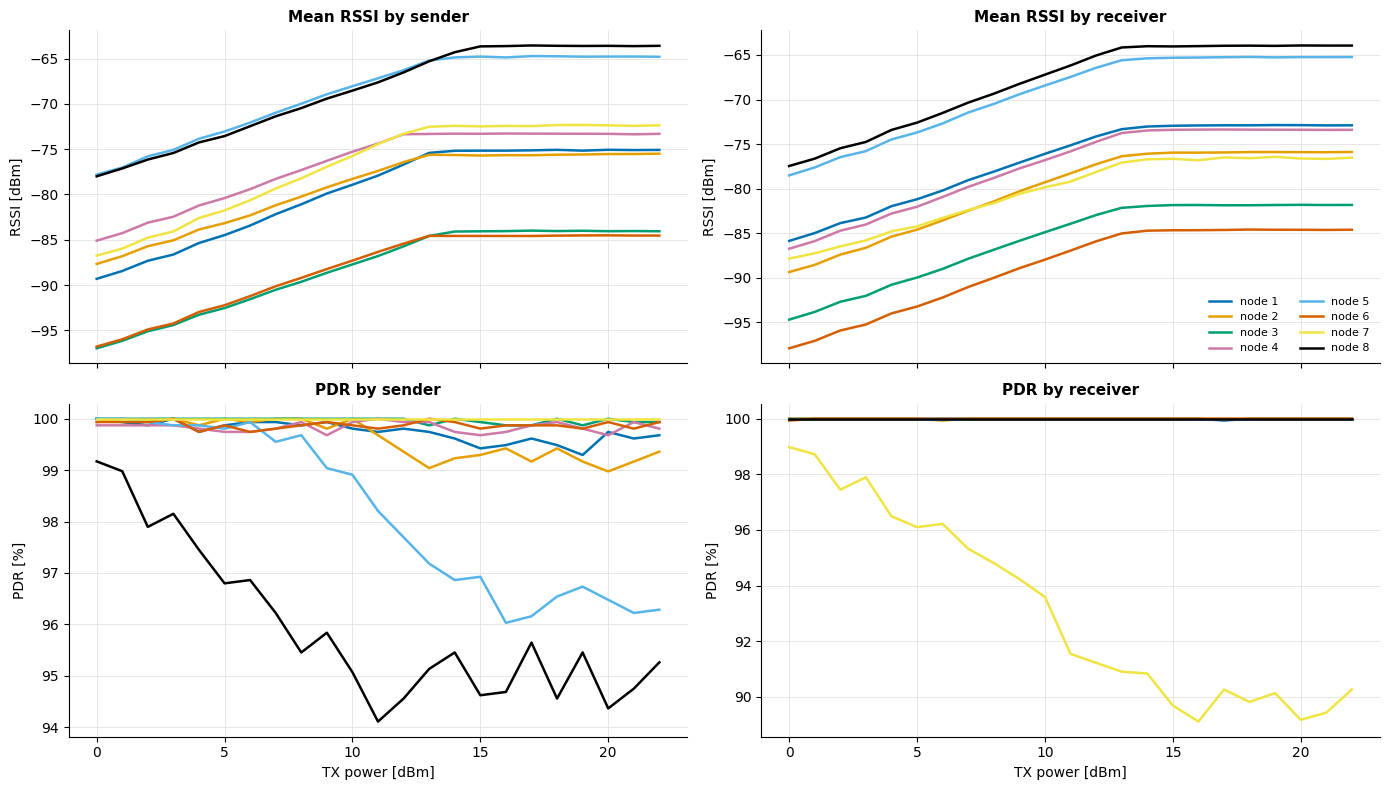

In [12]:
node_color = {n: NODE_COLORS[i % len(NODE_COLORS)] for i, n in enumerate(nodes)}
df["pdr"] = df["ok"] * 100.0

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
panels = [
    (axes[0, 0], "sender_id", ok, "rssi", "Mean RSSI by sender", "RSSI [dBm]"),
    (axes[0, 1], "receiver_id", ok, "rssi", "Mean RSSI by receiver", "RSSI [dBm]"),
    (axes[1, 0], "sender_id", df, "pdr", "PDR by sender", "PDR [%]"),
    (axes[1, 1], "receiver_id", df, "pdr", "PDR by receiver", "PDR [%]"),
]
for ax, role, subset, value, title, ylabel in panels:
    tab = subset.groupby(["tx_power", role])[value].mean().unstack(role)
    for n in tab.columns:
        ax.plot(tab.index, tab[n], color=node_color[n], lw=1.8, label=f"node {n}")
    ax.set(title=title, ylabel=ylabel)
axes[1, 0].set_xlabel("TX power [dBm]")
axes[1, 1].set_xlabel("TX power [dBm]")
axes[0, 1].legend(ncol=2, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

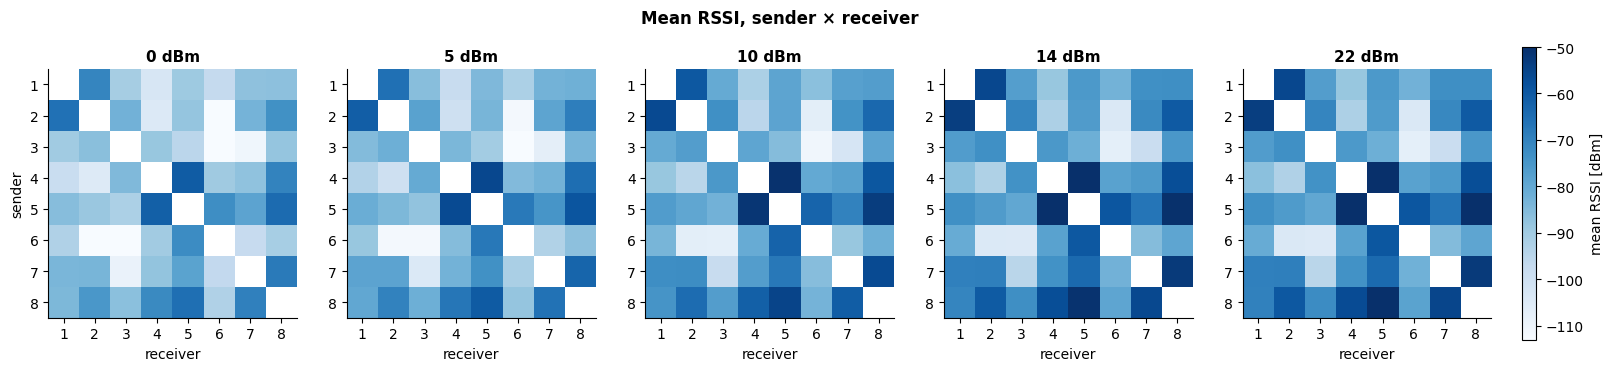

In [13]:
# Sender x receiver matrices at the reference powers
def node_matrix(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    return frame.pivot_table(index="sender_id", columns="receiver_id", values=value,
                             aggfunc="mean").reindex(index=nodes, columns=nodes)


fig, axes = plt.subplots(1, len(ref), figsize=(3.6 * len(ref) + 1.5, 3.8), squeeze=False)
vmin, vmax = ok["rssi"].quantile(0.02), ok["rssi"].quantile(0.98)
for ax, p in zip(axes[0], ref):
    im = ax.imshow(node_matrix(ok[ok["tx_power"] == p], "rssi").to_numpy(float), cmap="Blues", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(nodes)), nodes)
    ax.set_yticks(range(len(nodes)), nodes)
    ax.set(title=f"{p} dBm", xlabel="receiver")
    ax.grid(False)
axes[0, 0].set_ylabel("sender")
fig.colorbar(im, ax=axes.ravel().tolist(), label="mean RSSI [dBm]", fraction=0.025, pad=0.02)
fig.suptitle("Mean RSSI, sender × receiver", fontweight="bold")
plt.show()

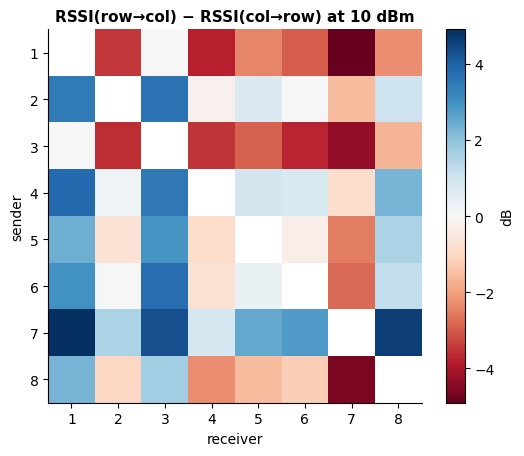

In [14]:
# Link asymmetry: RSSI(a->b) - RSSI(b->a). Reciprocal radio links should be close to 0.
if ASYM_POWER in powers:
    m = node_matrix(ok[ok["tx_power"] == ASYM_POWER], "rssi")
    asym = m - m.T
    lim = max(3.0, float(np.nanmax(np.abs(asym.to_numpy()))))
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    im = ax.imshow(asym.to_numpy(float), cmap="RdBu", norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim))
    ax.set_xticks(range(len(nodes)), nodes)
    ax.set_yticks(range(len(nodes)), nodes)
    ax.set(title=f"RSSI(row→col) − RSSI(col→row) at {ASYM_POWER} dBm", xlabel="receiver", ylabel="sender")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="dB")
    plt.tight_layout()
    plt.show()
else:
    print(f"ASYM_POWER={ASYM_POWER} not in the data")

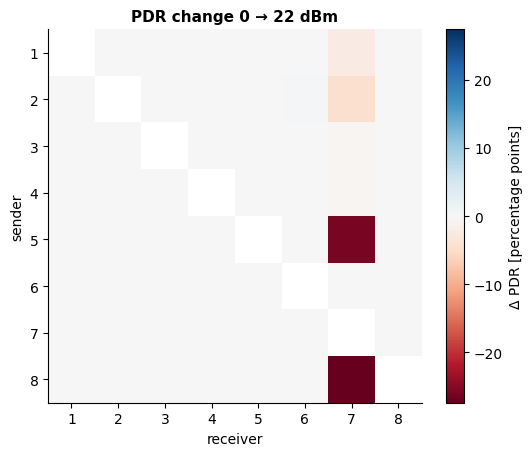

Links whose PDR dropped most when going to the higher power:


tx_power,0,22,delta
link,,,
8→7,94.20,66.82,-27.38
5→7,100.00,73.99,-26.01
2→7,100.00,95.52,-4.48
1→7,100.00,97.76,-2.24
4→7,99.11,98.65,-0.45
3→7,100.00,99.55,-0.45
6→7,99.55,99.55,-0.00
1→5,100.00,100.00,0.00


In [15]:
# PDR change between a low and a high power: where does raising power help (blue) or hurt (red)?
lo_p, hi_p = PDR_DIFF_POWERS
if lo_p in powers and hi_p in powers:
    diff = node_matrix(df[df["tx_power"] == hi_p], "pdr") - node_matrix(df[df["tx_power"] == lo_p], "pdr")
    lim = max(1.0, float(np.nanmax(np.abs(diff.to_numpy()))))
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    im = ax.imshow(diff.to_numpy(float), cmap="RdBu", norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim))
    ax.set_xticks(range(len(nodes)), nodes)
    ax.set_yticks(range(len(nodes)), nodes)
    ax.set(title=f"PDR change {lo_p} → {hi_p} dBm", xlabel="receiver", ylabel="sender")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="Δ PDR [percentage points]")
    plt.tight_layout()
    plt.show()

    worst = link_stats[link_stats["tx_power"].isin([lo_p, hi_p])].pivot(index="link", columns="tx_power",
                                                                          values="pdr_pct")
    worst["delta"] = worst[hi_p] - worst[lo_p]
    print("Links whose PDR dropped most when going to the higher power:")
    display(worst.sort_values("delta").head(8).round(2))
else:
    print(f"PDR_DIFF_POWERS={PDR_DIFF_POWERS} not both in the data")

## 7. RSSI vs SNR
One dot per `(link, power)` mean, coloured by TX power.

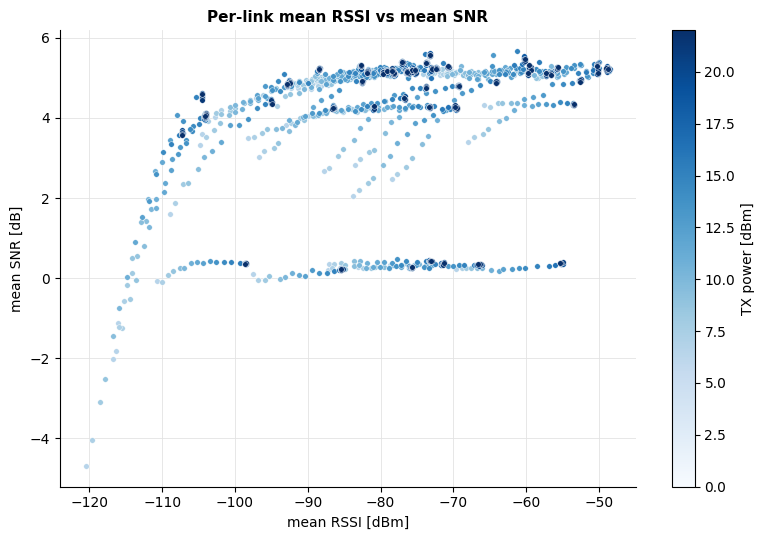

In [16]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for p in powers:
    d = link_stats[link_stats["tx_power"] == p]
    ax.scatter(d["rssi_mean"], d["snr_mean"], s=16, color=POWER_COLOR[p], edgecolor="white", lw=0.3)
fig.colorbar(plt.cm.ScalarMappable(cmap=_cmap, norm=plt.Normalize(powers[0], powers[-1])), ax=ax,
             label="TX power [dBm]")
ax.set(title="Per-link mean RSSI vs mean SNR", xlabel="mean RSSI [dBm]", ylabel="mean SNR [dB]")
plt.tight_layout()
plt.show()

## 8. Stability over time and temperature
Because the powers are interleaved, a parallel drift of all curves points to the environment
(temperature, interference), while a change of only one curve points to that power level.

valid BME samples: 0.0% of rows (only nodes 5-8 as receiver have a sensor)
No plausible BME readings in this dataset -> temperature panel and correlation are skipped.


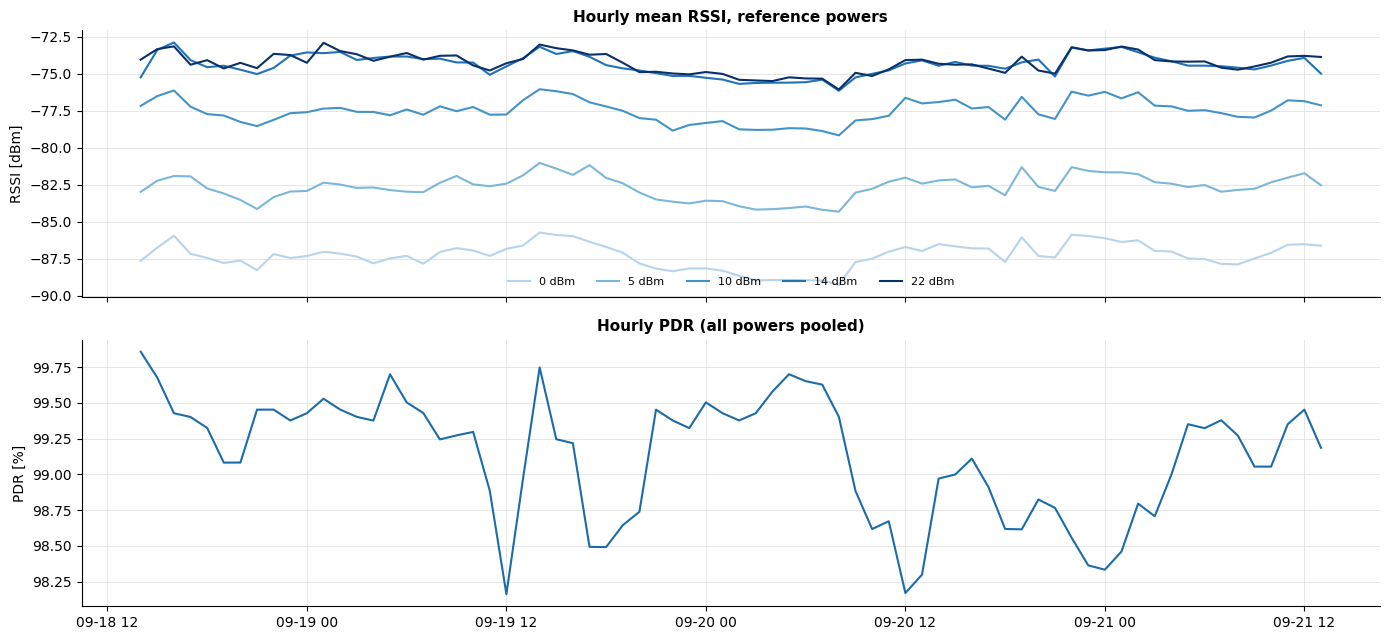

In [17]:
df["hour"] = df["pc_ts"].dt.floor("h")
ok = df[df["ok"]]

hourly_rssi = ok[ok["tx_power"].isin(ref)].groupby(["hour", "tx_power"])["rssi"].mean().unstack("tx_power")
hourly_pdr = df.groupby("hour")["ok"].mean() * 100.0

# Zero / garbage BME readings (failed reads, sensor stuck at 180.3 °C / 100 % / 6504.7 hPa) are ignored
bme_valid = df["bme_temp"].between(-30, 60) & df["bme_hum"].between(1, 100) & df["bme_press"].between(800, 1100)
hourly_temp = df[bme_valid].groupby("hour")["bme_temp"].mean()
has_temp = bool(bme_valid.any())
print(f"valid BME samples: {bme_valid.mean() * 100:.1f}% of rows (only nodes 5-8 as receiver have a sensor)")
if not has_temp:
    print("No plausible BME readings in this dataset -> temperature panel and correlation are skipped.")

fig, axes = plt.subplots(3 if has_temp else 2, 1, figsize=(14, 9 if has_temp else 6.5), sharex=True)
for p in ref:
    axes[0].plot(hourly_rssi.index, hourly_rssi[p], color=POWER_COLOR[p], lw=1.5, label=f"{p} dBm")
axes[0].set(title="Hourly mean RSSI, reference powers", ylabel="RSSI [dBm]")
axes[0].legend(ncol=len(ref), loc="lower center", fontsize=8)
axes[1].plot(hourly_pdr.index, hourly_pdr, color=ACCENT, lw=1.5)
axes[1].set(title="Hourly PDR (all powers pooled)", ylabel="PDR [%]")
if has_temp:
    axes[2].plot(hourly_temp.index, hourly_temp, color=INK, lw=1.5)
    axes[2].set(title="Hourly mean BME temperature (valid readings only)", ylabel="[°C]")
plt.tight_layout()
plt.show()

In [18]:
# RSSI residual (sample minus the mean of its own link+power) vs temperature: any dB/°C sensitivity?
lin = ok[ok["tx_power"].isin(linear_powers) & bme_valid.loc[ok.index]].copy()
lin["resid"] = lin["rssi"] - lin.groupby(["tx_power", "link"])["rssi"].transform("mean")
h = lin.groupby("hour").agg(resid=("resid", "mean"), temp=("bme_temp", "mean")).dropna()

if has_temp and len(h) >= 3:
    slope, icpt = np.polyfit(h["temp"], h["resid"], 1)
    r = h["temp"].corr(h["resid"])
    fig, ax = plt.subplots(figsize=(7, 4.4))
    ax.scatter(h["temp"], h["resid"], s=18, color=ACCENT, alpha=0.7)
    xs = np.array([h["temp"].min(), h["temp"].max()])
    ax.plot(xs, icpt + slope * xs, color=WARN, lw=1.5)
    ax.set(title=f"RSSI residual vs temperature (r = {r:.2f}, {slope:+.3f} dB/°C)",
           xlabel="hourly mean temperature [°C]", ylabel="hourly mean RSSI residual [dB]")
    plt.tight_layout()
    plt.show()
else:
    print("No valid temperature data for a correlation.")

No valid temperature data for a correlation.


## 9. Key numbers and export

In [19]:
lo_row, hi_row = summary.iloc[0], summary.iloc[-1]
print(f"TX power {powers[0]} -> {powers[-1]} dBm: mean RSSI {lo_row['rssi_mean']:.1f} -> {hi_row['rssi_mean']:.1f} dBm "
      f"({hi_row['rssi_mean'] - lo_row['rssi_mean']:+.1f} dB, ideal {powers[-1] - powers[0]:+d} dB)")
print(f"mean SNR {lo_row['snr_mean']:.1f} -> {hi_row['snr_mean']:.1f} dB")
print(f"PDR {lo_row['pdr_pct']:.2f}% -> {hi_row['pdr_pct']:.2f}%  "
      f"(best {summary['pdr_pct'].idxmax()} dBm = {summary['pdr_pct'].max():.2f}%, "
      f"worst {summary['pdr_pct'].idxmin()} dBm = {summary['pdr_pct'].min():.2f}%)")
print(f"RSSI saturates above {sat_power} dBm; stable >= {PDR_TARGET_PCT:g}% PDR reached on "
      f"{int(min_power.notna().sum())}/{len(min_power)} links")
print(f"e2e latency (ok links): median of medians {summary['e2e_ms_median'].median():.0f} ms, "
      f"spread of medians across powers {summary['e2e_ms_median'].max() - summary['e2e_ms_median'].min():.0f} ms")

CSV_DIR.mkdir(parents=True, exist_ok=True)
summary.round(4).to_csv(OUT_SUMMARY_PATH)
link_stats.drop(columns="link").round(4).to_csv(OUT_LINKS_PATH, index=False)
print(f"\nSummary written: {OUT_SUMMARY_PATH.resolve()}")
print(f"Link stats written: {OUT_LINKS_PATH.resolve()}")

TX power 0 -> 22 dBm: mean RSSI -87.3 -> -74.3 dBm (+13.0 dB, ideal +22 dB)
mean SNR 3.4 -> 4.4 dB
PDR 99.86% -> 98.78%  (best 0 dBm = 99.86%, worst 16 dBm = 98.64%)
RSSI saturates above 13 dBm; stable >= 95% PDR reached on 54/56 links
e2e latency (ok links): median of medians 4267 ms, spread of medians across powers 32 ms

Summary written: /home/duchieuvn/Code/stefan/SOFTWARE/master/runs_power_csv/power_summary.csv
Link stats written: /home/duchieuvn/Code/stefan/SOFTWARE/master/runs_power_csv/power_link_stats.csv
